# Testnet statistics

Read-only charts over the live testnet's JSON API: no database access, no keys, no writes.

| Panel | Question it answers |
| --- | --- |
| Chain overview | how far along is the chain, how busy is the pool? |
| Throughput over time | how many transactions land, and when? |
| Confirmation speed | how long does a transaction wait for a block? |
| Wallets | how many addresses has the chain seen, how is value distributed? |
| Synthetic wallets | what are the ten traffic-bot wallets doing over time? |
| Transfer graph | who sends to whom? |
| Miner graph | who plays whom, and who wins? |

## Running it

```bash
python -m venv .venv-analysis
.venv-analysis/bin/python -m pip install -e .                    # for the bot's wallets
.venv-analysis/bin/python -m pip install -r analysis/requirements.txt
.venv-analysis/bin/python -m jupyter lab analysis/testnet_stats.ipynb
```

Launch with `python -m jupyter` from the environment you installed into: the `jupyter` on
`PATH` is often another install, so an error saying `jupyter-lab` was not found means that
launcher has no JupyterLab, not that this notebook does. VS Code can open the file
directly — select `.venv-analysis` as the kernel.

Set `SCCP_NODE_URL` to point at another node, `SCCP_ANALYSIS_REFRESH=1` to ignore the
on-disk cache, and `SCCP_ANALYSIS_MAX_BLOCKS` / `_MAX_BODIES` / `_MAX_ACCOUNTS` /
`_MAX_GAMES` to trade depth for speed.

## What the chain can and cannot tell you

* **There is no "list every address" endpoint.** "Wallets" below means every address that
  appears in an adopted block (senders, recipients, coinbase payees) plus every rated
  miner. An address that has never transacted and never mined is invisible.
* **Blocks carry timestamps, transactions do not.** Submit-to-mined latency cannot be
  reconstructed after the fact; the notebook measures the block interval, which bounds
  it, and labels it as such.
* **The bottom of the chain is not from this year.** Genesis is the network's premine and
  its timestamp is a constant from `genesis/<network>.json` (`1700000000`, 2023-11-14, on
  testnet), part of the pinned genesis hash - and the deploy builds its bootstrap blocks
  (heights 1 to `bootstrap_end_height`, 19 on testnet) one target interval apart from that
  constant instead of from the wall clock. So a chain deployed today carries about twenty
  blocks dated 2023, two and a half years before its first real block; that is also the
  explorer's "1095d ago" label. They are reported on their own row and excluded from the
  time axes and interval statistics below, because one such cluster turns the first
  interval into a multi-year "confirmation" and divides throughput by the chain's age.
  Only a new genesis document could re-date block 0, and that would change the genesis
  hash; `deploy/bootstrap_*_stack.py` now stamps new bootstraps with the wall clock.
* **Balances come from two places.** Current balances are `GET /v1/accounts/{address}`;
  the balance history of the synthetic wallets is reconstructed from their transfers and
  anchored to that authoritative total (the drift check cell proves the anchor holds).
* **The ten synthetic wallets** are the ones `deploy/synthetic_testnet_traffic.py`
  derives: the same index always yields the same key, so they are recognisable from the
  chain alone.
* **Proofs are wins.** A draw never settles as a proof, so every game in the miner graph
  has a winner and a loser.

In [1]:
%matplotlib inline
import json
import os
import sys
from pathlib import Path

try:
    import httpx
    import matplotlib.pyplot as plt
    import networkx as nx
    import pandas as pd
except ModuleNotFoundError as exc:  # a fresh venv, or the wrong kernel
    raise ImportError(
        f"{exc.name!r} is missing from the kernel's interpreter ({sys.executable}).\n"
        "Install the analysis requirements into that interpreter:\n"
        "    python -m pip install -e . -r analysis/requirements.txt\n"
        "Then pick it as the kernel, or relaunch with:\n"
        "    python -m jupyter lab analysis/testnet_stats.ipynb"
    ) from exc

NODE_URL = os.environ.get(
    "SCCP_NODE_URL", "http://testnet.somecryptochessproject.com:8645"
).rstrip("/")
CACHE = Path("cache")
CACHE.mkdir(exist_ok=True)
REFRESH = bool(os.environ.get("SCCP_ANALYSIS_REFRESH"))

MAX_BLOCKS = int(os.environ.get("SCCP_ANALYSIS_MAX_BLOCKS", "400"))
MAX_BODIES = int(os.environ.get("SCCP_ANALYSIS_MAX_BODIES", "80"))
MAX_ACCOUNTS = int(os.environ.get("SCCP_ANALYSIS_MAX_ACCOUNTS", "80"))
MAX_GAMES = int(os.environ.get("SCCP_ANALYSIS_MAX_GAMES", "400"))
PAGE = 200  # the API's own ceiling on ?limit=
COIN = 100_000_000  # base units per coin

plt.rcParams.update(
    {
        "figure.figsize": (13, 4.5),
        "axes.grid": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 11,
    }
)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)

print(f"node: {NODE_URL}")

node: http://testnet.somecryptochessproject.com:8645


In [2]:
REPO = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
for entry in (str(REPO), str(REPO / "src")):
    if entry not in sys.path:
        sys.path.insert(0, entry)

try:
    from deploy.synthetic_testnet_traffic import wallet as traffic_wallet

    SYNTHETIC = {traffic_wallet(index).address: f"traffic-{index}" for index in range(10)}
except Exception as exc:  # the notebook still works without the bot's keys
    print(f"warning: cannot derive the synthetic wallets ({exc})")
    print("         they will look like any other wallet below")
    SYNTHETIC = {}

print(f"{len(SYNTHETIC)} synthetic wallets")
for address, name in SYNTHETIC.items():
    print(f"  {name:<10} {address}")

10 synthetic wallets
  traffic-0  sccpt1q84rwxucfjw45pl7tpeu7594eqqxwnheuk8w6me436gv5easan5hccxa24v
  traffic-1  sccpt1qyx3unll7t559h60l0yshhacdnv32eavzw49eqjx5knkvcvhc506sfgkskc
  traffic-2  sccpt1q8ukgkpfgpp6lqj2p6lcjgwej0zt0d3fj4sehmah47tygtymetf6605qnnh
  traffic-3  sccpt1q8gmuajgemksphjr3cg7j6mr437cvygh8pgxwqvzlqa0ac3f8mzp5ac5rcj
  traffic-4  sccpt1q9h7p46kv0h9cwwq336t9vpf8gwkgshwpukmxklx4lp79vql3u5njtx95ey
  traffic-5  sccpt1q82csvxctmlj4rpdrsgwgmyakcu9msu9frfcdyr63ts8ga26n5awy8vwpcu
  traffic-6  sccpt1q89hdnehpzfd86mtn2a6s5yslqmyngzyrk8na6jcdmmpq79f5qyzc9menx6
  traffic-7  sccpt1qx8majgrarq6rrlt6fmjjp3qmlujg5qpprzkxygsldgggch5x4xn7hyl2mq
  traffic-8  sccpt1q9ndwq3cdvs7f4lna3v6e4wgk38vzrtqf809yagq64rq2lqtd57mkmfagem
  traffic-9  sccpt1qxt8tfy3zacp89hpguy79r0n0s7fgyzu7s85te72x7d7jyhdzsadqntkq86


In [3]:
CLIENT = httpx.Client(base_url=NODE_URL, timeout=30.0, headers={"accept": "application/json"})


def get(path, **params):
    """One GET, dropping query parameters that are None."""
    response = CLIENT.get(path, params={k: v for k, v in params.items() if v is not None})
    response.raise_for_status()
    return response.json()


def page(path, key, limit):
    """Walk a ``before_height``-paged list endpoint until ``limit`` rows are collected.

    The cursor is exclusive: the node documents it as "the lowest height you already
    have", so it is passed through unchanged and the loop stops once it reaches genesis.
    """
    rows, before = [], None
    while len(rows) < limit:
        payload = get(path, limit=min(PAGE, limit - len(rows)), before_height=before)
        batch = list(payload.get(key) or ())
        if not batch:
            break
        rows.extend(batch)
        heights = [row["height"] for row in batch if row.get("height") is not None]
        if not heights:  # a page of mempool-only rows: nothing older to ask for
            break
        before = min(heights)
        if before <= 0:  # genesis reached
            break
    return rows


def snapshot(name, path, key, limit):
    """``page`` with an on-disk cache, so re-running a cell is free."""
    cached = CACHE / f"{name}-{limit}.json"
    if cached.exists() and not REFRESH:
        return json.loads(cached.read_text())
    rows = page(path, key, limit)
    cached.write_text(json.dumps(rows))
    return rows


def block_bodies(heights):
    """Full blocks for ``heights``: the bodies are where the transactions live."""
    cached = CACHE / "bodies.json"
    store = json.loads(cached.read_text()) if cached.exists() and not REFRESH else {}
    missing = [h for h in heights if str(h) not in store]
    for height in missing:
        store[str(height)] = get(f"/v1/blocks/{height}")["block"]
    if missing or REFRESH:
        cached.write_text(json.dumps(store))
    return {int(height): body for height, body in store.items()}


def account(address):
    """``GET /v1/accounts/{address}``, tolerating an address this node will not serve."""
    try:
        return get(f"/v1/accounts/{address}")
    except httpx.HTTPError as exc:
        print(f"  skipped {short(address)}: {exc}")
        return None


def short(address):
    """A readable label: the bot's wallets keep their name, everything else is elided."""
    if not address:
        return "?"
    if address in SYNTHETIC:
        return SYNTHETIC[address]
    return f"{address[:11]}...{address[-4:]}"

## Chain overview

One `GET /v1/status` plus a page of `GET /v1/blocks` is enough for the headline numbers.
"Transactions in window" counts only what the sampled blocks carry, so it is a lower bound
on the chain's history, not a total.

In [4]:
status = get("/v1/status")

blocks = pd.DataFrame(snapshot("blocks", "/v1/blocks", "blocks", MAX_BLOCKS))
blocks = blocks.sort_values("height").reset_index(drop=True)
blocks["time"] = pd.to_datetime(blocks["timestamp"], unit="s", utc=True)

# The bottom of the chain is not from this year, twice over. Height 0 is the premine block
# from `genesis/<network>.json`, stamped with a pinned constant (1700000000, 2023-11-14, on
# testnet and devnet) that is part of the genesis hash; and the deploy mined its bootstrap
# blocks up to `bootstrap_end_height` at `tip + target_block_seconds` from that stamp, so
# the whole setup window reads as 2023 even on a chain deployed today. Both are consensus
# data already on disk -- the stamp cannot be edited without a new genesis -- so they are
# reported, not re-dated, and kept out of the frame below: one cluster of points years away
# from the tip stretches every time axis, turns the first interval into a multi-year
# "confirmation" and divides throughput by the chain's whole age.
try:
    from sccp.chain.block import bootstrap_end_height
    from sccp.config import get_network

    bootstrap_tip = bootstrap_end_height(get_network(status["network"]))
    excluded = "bootstrap excluded"
except Exception as exc:  # the charts still work, they just span the whole chain
    print(f"warning: cannot resolve the bootstrap window ({exc}); excluding genesis only")
    bootstrap_tip, excluded = 0, "genesis excluded"

setup = blocks[blocks["height"] <= bootstrap_tip].reset_index(drop=True)
blocks = blocks[blocks["height"] > bootstrap_tip].reset_index(drop=True)
if blocks.empty:
    raise SystemExit(
        f"the node at height {status['height']} has not mined past height {bootstrap_tip}: "
        "nothing to chart"
    )
blocks["interval"] = blocks["timestamp"].diff()

window = blocks["time"].iloc[-1] - blocks["time"].iloc[0]
hours = max(window.total_seconds() / 3600, 1e-9)

if len(setup):
    first, last = setup["time"].iloc[0], setup["time"].iloc[-1]
    gap = (blocks["time"].iloc[0] - last) / pd.Timedelta("1D")
    setup_row = (
        f"{len(setup):,} blocks {first:%Y-%m-%d %H:%M} -> {last:%H:%M} UTC, "
        f"{gap:,.0f} d before block {int(blocks['height'].iloc[0])}"
    )
else:
    setup_row = "none in the sampled window"

overview = pd.Series(
    {
        "network": status["network"],
        "height (tip)": f"{status['height']:,}",
        "tip hash": f"{status['tip_hash'][:16]}...",
        "peers": status["peers"],
        "syncing": status["syncing"],
        "mempool transactions": status["mempool"]["transactions"],
        "mempool proofs": status["mempool"]["proofs"],
        "blocks sampled": f"{len(blocks):,} ({excluded})",
        "sample window": f"{hours:.1f} h",
        "setup blocks": setup_row,
        "transactions in window": f"{int(blocks['transactions'].sum()):,}",
        "transactions per hour": f"{int(blocks['transactions'].sum()) / hours:,.1f}",
        "median block interval": f"{blocks['interval'].median():.1f} s",
    },
    name="value",
)
overview.to_frame()

,value
network,testnet
height (tip),75
tip hash,550c26fbf0fdbf9d...
peers,0
syncing,False
mempool transactions,1
mempool proofs,0
blocks sampled,56 (bootstrap excluded)
sample window,0.9 h
setup blocks,"20 blocks 2023-11-14 22:13 -> 22:32 UTC, 1,095..."


## Throughput over time

Every block on the adopted branch carries a transaction count, and the sample is taken
tip-first so the right edge of each chart is "now". The step chart is the chain's age in
transactions; the bars are what one block carries; the 5-minute buckets are what a
client would see as arrival rate. A flat cumulative line with bars underneath means the
chain is ticking but nobody is spending; stairs with gaps mean bursts followed by quiet.

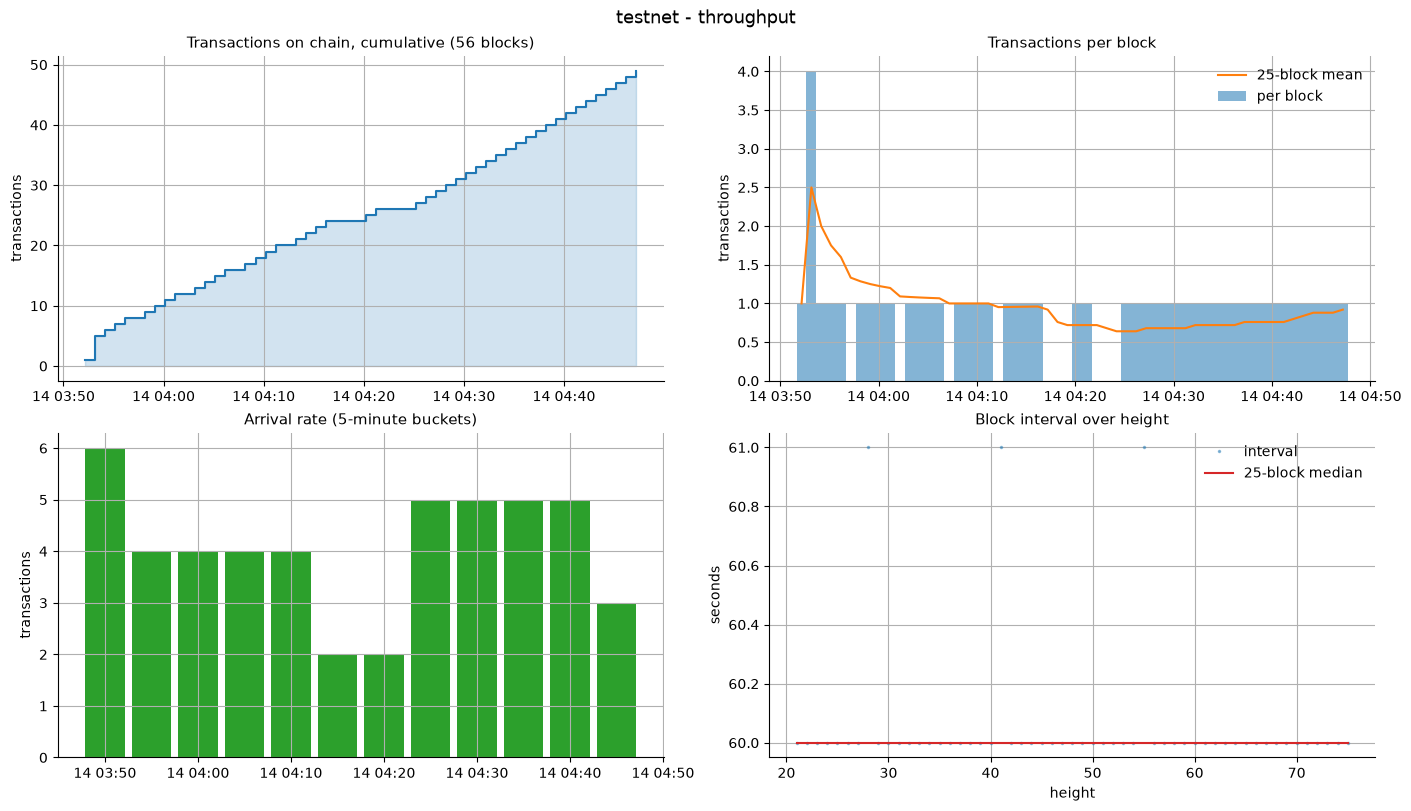

In [5]:
step = pd.Timedelta(seconds=float(blocks["interval"].median() or 60))
bucket = max(pd.Timedelta(minutes=5), (window / 40) if window.total_seconds() else pd.Timedelta(minutes=5))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
cells = axes.ravel()

ax = cells[0]
ax.step(blocks["time"], blocks["transactions"].cumsum(), where="post", color="C0")
ax.fill_between(
    blocks["time"], blocks["transactions"].cumsum(), step="post", color="C0", alpha=0.2
)
ax.set(title=f"Transactions on chain, cumulative ({len(blocks):,} blocks)", ylabel="transactions")

ax = cells[1]
ax.bar(blocks["time"], blocks["transactions"], width=step, alpha=0.55, label="per block")
ax.plot(
    blocks["time"],
    blocks["transactions"].rolling(25, min_periods=1).mean(),
    color="C1",
    label="25-block mean",
)
ax.set(title="Transactions per block", ylabel="transactions")
ax.legend(frameon=False)

ax = cells[2]
rate = blocks.set_index("time")["transactions"].resample(bucket).sum()
ax.bar(rate.index, rate.values, width=bucket * 0.85, color="C2")
ax.set(title=f"Arrival rate ({bucket.total_seconds() / 60:.0f}-minute buckets)", ylabel="transactions")

ax = cells[3]
ax.plot(blocks["height"], blocks["interval"], ".", ms=3, alpha=0.45, label="interval")
ax.plot(
    blocks["height"],
    blocks["interval"].rolling(25, min_periods=1).median(),
    color="C3",
    label="25-block median",
)
ax.set(title="Block interval over height", xlabel="height", ylabel="seconds")
ax.legend(frameon=False)

fig.suptitle(f"{status['network']} - throughput", fontsize=13)
plt.show()

## Transaction speed

The chain records one timestamp per block, not per transaction, so submit-to-mined
latency is not recoverable after the fact. What is measurable is the cadence a
transaction is subject to: `POST /v1/tx` and `POST /v1/faucet` accept into the mempool and
return immediately, and the next block a miner builds includes them. A transaction
therefore waits at most one **block interval** - the series below - plus the miner's
build time. The interval is also the chain's difficulty feedback: a retarget that shortens
it is miners adding work.

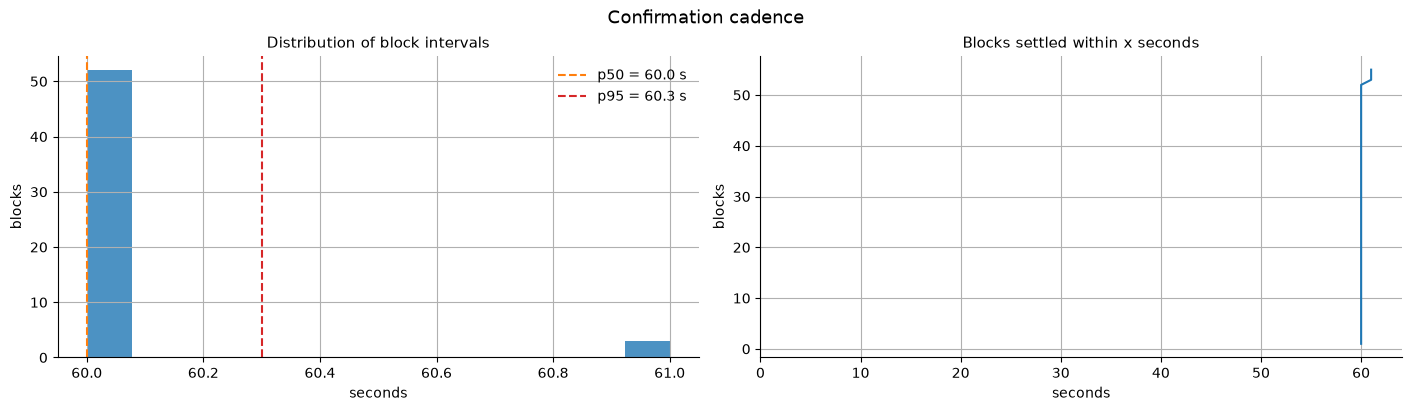

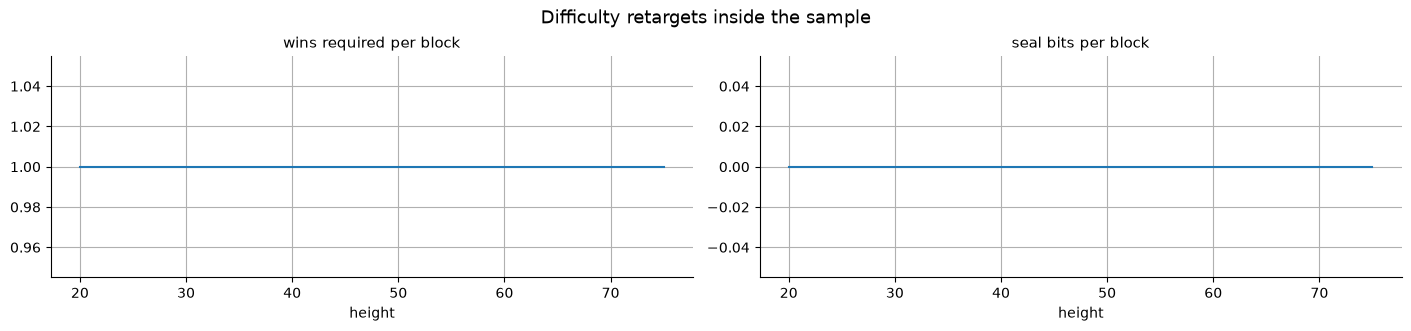

,seconds
count,55.000000
mean,60.054545
std,0.229184
min,60.000000
50%,60.000000
90%,60.000000
95%,60.300000
99%,61.000000
max,61.000000


In [6]:
intervals = blocks["interval"].dropna()
speed = intervals.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).rename("seconds").to_frame()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

ax = axes[0]
ax.hist(intervals, bins=min(60, max(10, len(intervals) // 4)), color="C0", alpha=0.8)
for q, colour in ((0.5, "C1"), (0.95, "C3")):
    value = float(intervals.quantile(q))
    ax.axvline(value, color=colour, ls="--", label=f"p{int(q * 100)} = {value:.1f} s")
ax.set(title="Distribution of block intervals", xlabel="seconds", ylabel="blocks")
ax.legend(frameon=False)

ax = axes[1]
ordered = intervals.sort_values().to_numpy()
ax.plot(ordered, range(1, len(ordered) + 1), color="C0")
ax.set(title="Blocks settled within x seconds", xlabel="seconds", ylabel="blocks")
ax.set_xlim(0, max(float(intervals.quantile(0.99)) * 1.05, 1.0))

fig.suptitle("Confirmation cadence", fontsize=13)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.2), constrained_layout=True, sharex=True)
blocks.plot(x="height", y="wins_required", ax=axes[0], title="wins required per block", legend=False)
blocks.plot(x="height", y="seal_bits", ax=axes[1], title="seal bits per block", legend=False)
fig.suptitle("Difficulty retargets inside the sample", fontsize=13)
plt.show()

speed

## Transactions

The block list only carries counts, so the newest `MAX_BODIES` blocks are fetched in full
to read the bodies. Each row is one transaction.

Two facts about the envelope matter here and are easy to get wrong:

* a **coinbase is not its own transaction type** - it is a `transfer` from the zero
  address, and only its position in the block (`Block.coinbase`) identifies it, so it is
  flagged from the envelope rather than from `type`;
* `payload.to` is the recipient for both a transfer and a coinbase; a transaction type
  with no recipient (registration, availability, reveal) shows an empty `recipient`.

Coinbases are the chain paying miners, so they belong in the counts but not in "who sends
coins to whom" - the graphs below exclude them.

In [7]:
heights = [int(h) for h in blocks["height"].tolist()[-MAX_BODIES:]]
BODIES = block_bodies(heights)

rows = []
for height in sorted(BODIES):
    body = BODIES[height]
    stamp = body["header"]["timestamp"]
    # A coinbase is a transfer from the zero address, and nothing on the wire says so:
    # its type is plain "transfer". Its place in the block envelope is the only marker.
    entries = [(body.get("coinbase"), True)] if body.get("coinbase") else []
    entries.extend((tx, False) for tx in body.get("transactions") or ())
    for tx, is_coinbase in entries:
        payload = tx.get("payload") or {}
        rows.append(
            {
                "height": height,
                "timestamp": stamp,
                "type": tx["type"],
                "sender": tx["from"],
                "recipient": payload.get("to"),
                "amount": int(payload.get("amount") or 0),
                "fee": int(tx["fee"]),
                "coinbase": is_coinbase,
            }
        )

txs = pd.DataFrame(rows)
txs["time"] = pd.to_datetime(txs["timestamp"], unit="s", utc=True)
txs["coins"] = txs["amount"] / COIN

print(
    f"{len(txs):,} transactions in {len(BODIES):,} blocks "
    f"(heights {min(BODIES):,}..{max(BODIES):,}), "
    f"{int(txs['coinbase'].sum()):,} of them coinbases"
)
txs["type"].value_counts().rename("count").to_frame()

105 transactions in 56 blocks (heights 20..75), 56 of them coinbases


,count
type,
transfer,85
availability,10
reveal,10


In [8]:
paid = txs[~txs["coinbase"] & txs["recipient"].notna()].copy()
paid["from"] = paid["sender"].map(short)
paid["to"] = paid["recipient"].map(short)

by_sender = (
    paid.groupby("from")
    .agg(sent=("coins", "sum"), transfers=("coins", "size"), fees=("fee", "sum"))
    .sort_values("transfers", ascending=False)
)
by_sender["fees"] = by_sender["fees"] / COIN
by_sender.head(15).round(4)

,sent,transfers,fees
from,,,
sccpt1qylr0...n3q3,74.0,29,0.0003


## Who sends to whom

Each directed edge is one ordered pair of wallets, weighted by the number of transfers and
the coins moved. Orange nodes are the ten synthetic wallets, blue nodes are everyone else
(often the faucet, which is the source of every coin in this graph). Node area is the
volume that flowed through the wallet, so a hub like the faucet is large; a leaf that only
ever receives is small.

The graph is truncated to the busiest `MAX_NODES` wallets so it stays readable - the table
above the chart says how many edges were drawn out of how many observed.

6 wallet pairs over 29 transfers; drawing 7 nodes / 6 edges


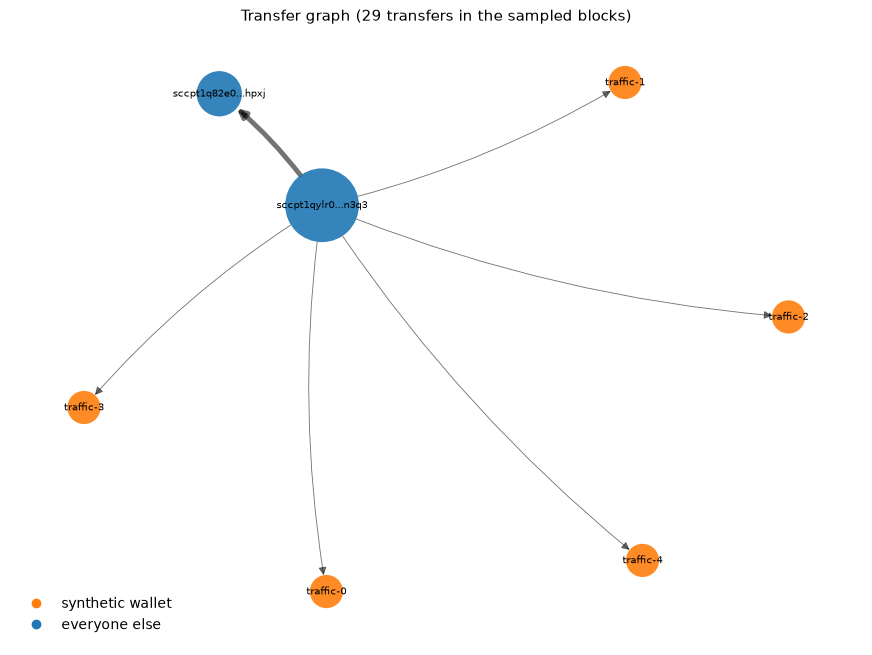

,sender,recipient,transfers,coins
0,sccpt1qylr0...n3q3,sccpt1q82e0...hpxj,24,24.0
1,sccpt1qylr0...n3q3,traffic-0,1,10.0
2,sccpt1qylr0...n3q3,traffic-3,1,10.0
3,sccpt1qylr0...n3q3,traffic-2,1,10.0
4,sccpt1qylr0...n3q3,traffic-4,1,10.0
5,sccpt1qylr0...n3q3,traffic-1,1,10.0


In [9]:
transfers = paid
edges = (
    transfers.groupby(["sender", "recipient"])
    .agg(transfers=("coins", "size"), coins=("coins", "sum"))
    .sort_values("transfers", ascending=False)
)

MAX_NODES = 40
volume = (
    pd.concat(
        [
            edges.groupby(level=0)["coins"].sum(),
            edges.groupby(level=1)["coins"].sum(),
        ],
        axis=1,
    )
    .fillna(0.0)
    .sum(axis=1)
    .sort_values(ascending=False)
)
kept = set(volume.index[:MAX_NODES])
drawn = edges[edges.index.get_level_values(0).isin(kept) & edges.index.get_level_values(1).isin(kept)]

G = nx.DiGraph()
for (sender, recipient), row in drawn.iterrows():
    G.add_edge(sender, recipient, weight=int(row["transfers"]), coins=float(row["coins"]))
for node in G.nodes:
    G.nodes[node]["synthetic"] = node in SYNTHETIC

print(
    f"{len(edges):,} wallet pairs over {len(transfers):,} transfers; "
    f"drawing {G.number_of_nodes()} nodes / {G.number_of_edges()} edges"
)

pos = nx.spring_layout(G, seed=11, k=1.5 / max(G.number_of_nodes(), 2) ** 0.5, iterations=400)
heaviest = max((d["weight"] for *_, d in G.edges(data=True)), default=1)
widths = [0.5 + 3.0 * G[u][v]["weight"] / heaviest for u, v in G.edges]
sizes = [220 + 2600 * volume[n] / max(float(volume[list(G.nodes)].max()), 1e-9) for n in G.nodes]
colours = ["C1" if G.nodes[n]["synthetic"] else "C0" for n in G.nodes]

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=sizes, node_color=colours, alpha=0.9, linewidths=0)
nx.draw_networkx_edges(
    G, pos, ax=ax, width=widths, alpha=0.55, arrows=True, arrowsize=12,
    connectionstyle="arc3,rad=0.08", node_size=sizes,
)
nx.draw_networkx_labels(G, pos, ax=ax, labels={n: short(n) for n in G.nodes}, font_size=7)
ax.legend(
    handles=[
        plt.Line2D([], [], marker="o", ls="", color="C1", label="synthetic wallet"),
        plt.Line2D([], [], marker="o", ls="", color="C0", label="everyone else"),
    ],
    loc="lower left",
    frameon=False,
)
ax.set_title(f"Transfer graph ({len(transfers):,} transfers in the sampled blocks)")
ax.axis("off")
plt.show()

top_edges = drawn.head(15).reset_index()
top_edges["sender"] = top_edges["sender"].map(short)
top_edges["recipient"] = top_edges["recipient"].map(short)
top_edges.round(4)

## Wallets and how tokens are distributed

There is no endpoint that enumerates addresses, so the denominator is every address the
sampled blocks mention: senders, recipients, coinbase payees and miners. Each one is then
resolved through `GET /v1/accounts/{address}`, which reports `balance` (spendable),
`immature` (coinbase rewards still vesting) and `total`.

A long tail below one coin next to a handful of large wallets is normal for a chain whose
coins arrive as coinbase rewards; the ten synthetic wallets sit in the tail because the
bot spends as fast as it is funded.

9 distinct addresses in the sampled blocks, 9 balances read, 9 holding a non-zero balance


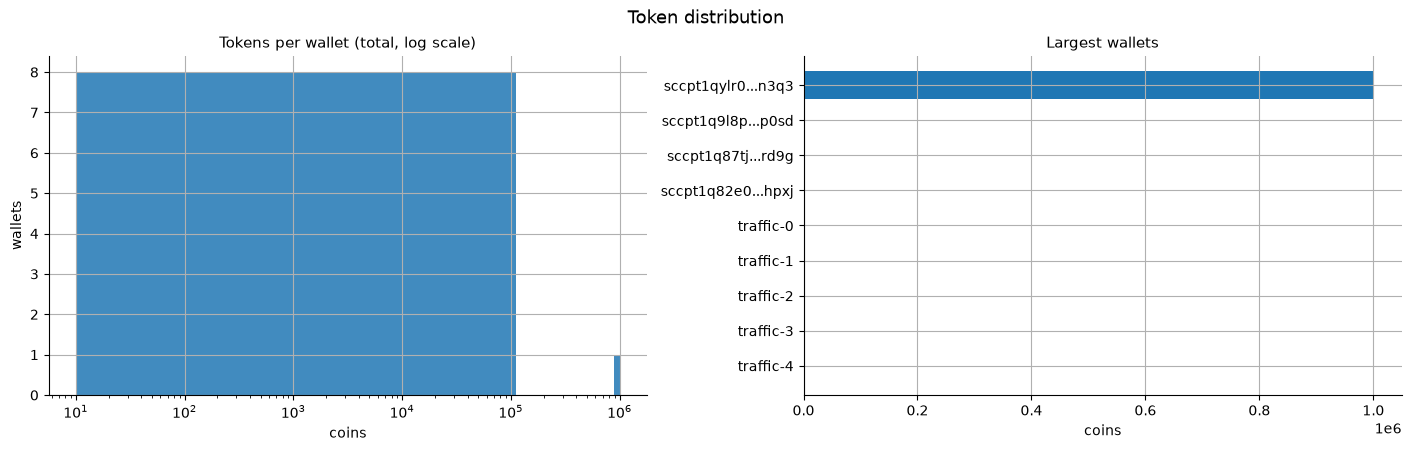

,balance,immature,total,nonce,synthetic
label,,,,,
sccpt1qylr0...n3q3,999725.9997,0.0000,999725.9997,31,False
sccpt1q9l8p...p0sd,589.9999,0.0000,599.9999,18,False
sccpt1q87tj...rd9g,540.0000,0.0002,550.0003,18,False
sccpt1q82e0...hpxj,24.0000,0.0000,24.0000,0,False
traffic-0,10.0000,0.0000,10.0000,0,True
traffic-1,10.0000,0.0000,10.0000,0,True
traffic-2,10.0000,0.0000,10.0000,0,True
traffic-3,10.0000,0.0000,10.0000,0,True
traffic-4,10.0000,0.0000,10.0000,0,True


In [10]:
seen = sorted(
    {a for a in set(txs["sender"]) | set(txs["recipient"].dropna()) | set(blocks["miner"]) if a}
)
activity = (
    pd.concat([paid["sender"].value_counts(), paid["recipient"].value_counts()], axis=1)
    .fillna(0)
    .sum(axis=1)
    .sort_values(ascending=False)
)
ordered = list(activity.index)[:MAX_ACCOUNTS]
for address in seen:
    if len(ordered) >= MAX_ACCOUNTS:
        break
    if address not in ordered:
        ordered.append(address)

rows = []
for address in ordered:
    view = account(address)
    if view is None:
        continue
    rows.append(
        {
            "address": address,
            "label": short(address),
            "synthetic": address in SYNTHETIC,
            "balance": view["balance"],
            "immature": view["immature"],
            "total": view["total"],
            "nonce": view["nonce"],
            "coins": view["total"] / COIN,
        }
    )

wallets = pd.DataFrame(rows).sort_values("total", ascending=False).reset_index(drop=True)
print(
    f"{len(seen):,} distinct addresses in the sampled blocks, "
    f"{len(wallets):,} balances read, "
    f"{int((wallets['total'] > 0).sum()):,} holding a non-zero balance"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), constrained_layout=True)

ax = axes[0]
funded = wallets.loc[wallets["total"] > 0, "coins"]
if not funded.empty:
    ax.hist(funded, bins=min(30, max(5, len(funded))), color="C0", alpha=0.85)
    ax.set_xscale("log")
ax.set(title="Tokens per wallet (total, log scale)", xlabel="coins", ylabel="wallets")

ax = axes[1]
top = wallets.loc[wallets["total"] > 0].head(15).iloc[::-1]
ax.barh(top["label"], top["coins"], color=["C1" if s else "C0" for s in top["synthetic"]])
ax.set(title="Largest wallets", xlabel="coins")
fig.suptitle("Token distribution", fontsize=13)
plt.show()

in_coins = wallets.assign(
    balance=lambda frame: (frame["balance"] / COIN).round(4),
    immature=lambda frame: (frame["immature"] / COIN).round(4),
    total=lambda frame: (frame["total"] / COIN).round(4),
)
in_coins.set_index("label")[["balance", "immature", "total", "nonce", "synthetic"]].head(20)

## The ten synthetic wallets over time

`GET /v1/accounts/{address}` is current state only, so history is rebuilt from the
transfers in the fetched bodies: every credit to a synthetic wallet is a positive step,
every transfer out is a negative step (amount plus fee). The reconstruction is then
anchored: each series is shifted so its final point equals the ledger's current `total`.
The drift printed below shows what that anchor costs - zero means every movement of these
wallets inside the window was captured, which is what the bot's behaviour implies (it only
ever receives grants and sends transfers, never mines).

Negative values are clipped in the area chart: a wallet funded *before* the sampled window
would otherwise draw backwards through zero. The line for the total is not clipped.

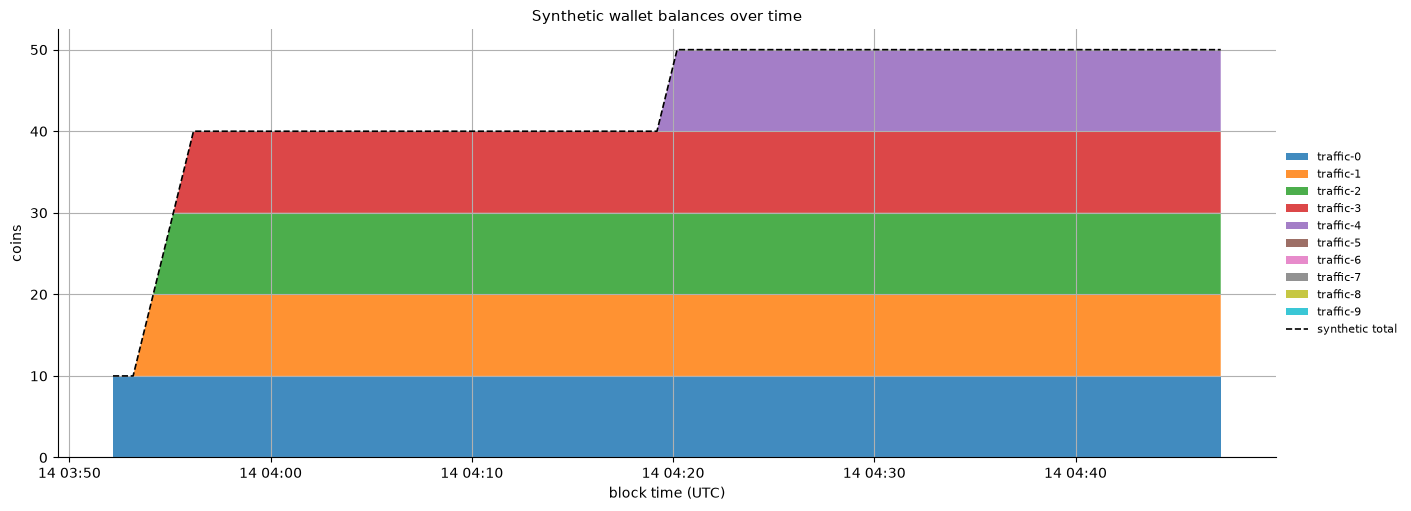

reconstruction vs ledger total: max drift 0.000000 coins


,coins,share of synthetic value,blocks with movement
wallet,,,
traffic-0,10.0,0.2,1
traffic-1,10.0,0.2,1
traffic-2,10.0,0.2,1
traffic-3,10.0,0.2,1
traffic-4,10.0,0.2,1
traffic-5,0.0,0.0,0
traffic-6,0.0,0.0,0
traffic-7,0.0,0.0,0
traffic-8,0.0,0.0,0


In [11]:
by_address = {address: name for address, name in SYNTHETIC.items()}
names = list(by_address.values())

events = []
for tx in txs.itertuples(index=False):
    if tx.coinbase:
        continue
    if tx.recipient in by_address:
        events.append((tx.height, by_address[tx.recipient], int(tx.amount)))
    if tx.sender in by_address:
        events.append((tx.height, by_address[tx.sender], -int(tx.amount) - int(tx.fee)))

window_heights = sorted(BODIES)
if not window_heights:
    raise RuntimeError("no block bodies were fetched; raise SCCP_ANALYSIS_MAX_BODIES")
if events:
    flow = (
        pd.DataFrame(events, columns=["height", "wallet", "delta"])
        .pivot_table(index="height", columns="wallet", values="delta", aggfunc="sum")
        .reindex(index=window_heights, columns=names)
        .fillna(0.0)
    )
else:
    flow = pd.DataFrame(0.0, index=window_heights, columns=names)

running = flow.cumsum() / COIN
ledger = wallets.set_index("label")["coins"].to_dict()
opening = pd.Series(
    {name: ledger.get(name, 0.0) - (running[name].iloc[-1] if name in running else 0.0) for name in names}
)
balances_over_time = running.add(opening, axis=1)
drift = (balances_over_time.iloc[-1] - pd.Series(ledger).reindex(names).fillna(0.0)).abs()

stamp = dict(zip(blocks["height"], blocks["time"]))
x = [stamp.get(height) for height in balances_over_time.index]

fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
if names:
    ax.stackplot(
        x,
        [balances_over_time[name].clip(lower=0.0) for name in names],
        labels=names,
        alpha=0.85,
    )
    ax.plot(x, balances_over_time.sum(axis=1), color="black", ls="--", lw=1.2, label="synthetic total")
    ax.legend(ncol=1, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
else:
    ax.text(0.5, 0.5, "no synthetic wallets on this node", ha="center", va="center")
    ax.set_xticks([])
    ax.set_yticks([])
ax.set(title="Synthetic wallet balances over time", xlabel="block time (UTC)", ylabel="coins")
plt.show()

if names:
    print(f"reconstruction vs ledger total: max drift {float(drift.max()):.6f} coins")
summary = pd.DataFrame(
    {
        "coins": balances_over_time.iloc[-1].round(4),
        "share of synthetic value": (
            balances_over_time.iloc[-1] / max(float(balances_over_time.iloc[-1].sum()), 1e-9)
        ).round(3),
        "blocks with movement": (flow != 0).sum(),
    }
)
summary.sort_values("coins", ascending=False)

## Who plays whom, and who wins

`GET /v1/games` lists settled proofs, newest first: one row per won game, with the winner,
the loser, the epoch, the round and the plies. A proof *is* a win - a draw never settles -
so every edge below reads "beat", never "drew with".

Miners are labelled by their rank on `GET /v1/ratings` (`miner-1` is the strongest), which
is the only stable name the protocol gives an address.

Two views over the same table:

* a directed graph, one edge per ordered pair, arrows from winner to loser and labelled
  with the number of games. A node with thick outgoing edges wins; thin reciprocal edges
  are the rematches.
* a win matrix, cell *(row, column)* = games the row player beat the column player.

In [12]:
games = pd.DataFrame(snapshot("games", "/v1/games", "games", MAX_GAMES))
settled = games[games["height"].notna()].copy()
settled["height"] = settled["height"].astype(int)
settled = settled.sort_values("height")

ratings = get("/v1/ratings", limit=1000)
ranks = {row["address"]: row for row in ratings["miners"]}


def miner(address):
    """The rank label of a miner, falling back to an elided address."""
    row = ranks.get(address)
    return f"miner-{row['rank']}" if row else short(address)


combatants = pd.unique(pd.concat([settled["winner"], settled["loser"].dropna()], ignore_index=True))
names = {address: miner(address) for address in combatants}

record = (
    pd.DataFrame(
        {
            "wins": settled["winner"].value_counts(),
            "losses": settled["loser"].dropna().value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
)
record["games"] = record["wins"] + record["losses"]
record["win_rate"] = (record["wins"] / record["games"]).round(3)
record = record.reindex(combatants).fillna(0).astype({"wins": int, "losses": int, "games": int})
record.index = [names[a] for a in record.index]
record = record.sort_values(["games", "wins"], ascending=False)

print(
    f"{len(games):,} games listed, {len(settled):,} settled on chain, "
    f"{int(games['in_mempool'].sum())} still in the pool"
)
print(f"{ratings['rated_epochs']} rated epochs, mean rating {ratings['distribution']['mean']:.1f}")
record

19 games listed, 19 settled on chain, 0 still in the pool
7 rated epochs, mean rating 1500.0


,wins,losses,games,win_rate
miner-2,10,9,19,0.526
miner-1,9,10,19,0.474


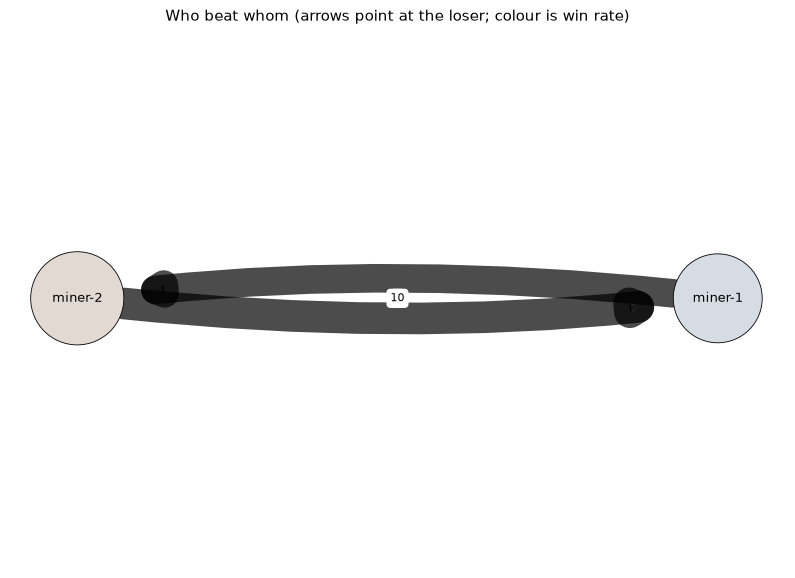

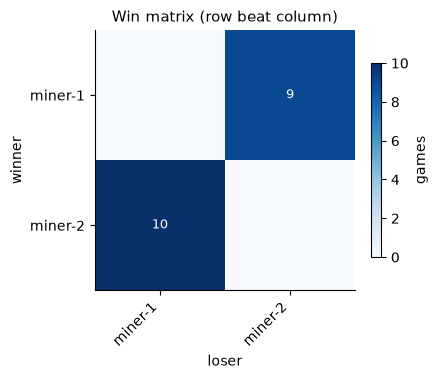

,miner-1,miner-2
miner-1,0,9
miner-2,10,0


In [13]:
M = nx.DiGraph()
for winner, loser in zip(settled["winner"], settled["loser"], strict=False):
    if not loser or winner == loser:
        continue
    M.add_edge(winner, loser, weight=M.get_edge_data(winner, loser, {}).get("weight", 0) + 1)

wins_by_address = {
    address: int(record.loc[names[address], "wins"]) for address in combatants if names[address] in record.index
}
rates = {address: float(record.loc[names[address], "win_rate"]) for address in combatants if names[address] in record.index}

pos = (
    nx.circular_layout(M)
    if M.number_of_nodes() <= 8
    else nx.spring_layout(M, seed=5, k=1.2 / max(M.number_of_nodes(), 2) ** 0.5)
)

if M.number_of_nodes():
    fig, ax = plt.subplots(figsize=(10, 7))
    heaviest_wins = max(max(wins_by_address.values(), default=1), 1)
    node_sizes = [500 + 4000 * wins_by_address.get(n, 0) / heaviest_wins for n in M.nodes]
    nx.draw_networkx_nodes(
        M, pos, ax=ax, node_size=node_sizes,
        node_color=[rates.get(n, 0.0) for n in M.nodes], cmap="coolwarm", vmin=0.0, vmax=1.0,
        edgecolors="black", linewidths=0.6,
    )
    nx.draw_networkx_edges(
        M, pos, ax=ax, width=[0.8 + 2.2 * d["weight"] for *_, d in M.edges(data=True)],
        alpha=0.7, arrows=True, arrowsize=16, node_size=node_sizes,
        connectionstyle="arc3,rad=0.06",
    )
    nx.draw_networkx_labels(M, pos, ax=ax, labels={n: names[n] for n in M.nodes}, font_size=9)
    nx.draw_networkx_edge_labels(
        M, pos, ax=ax, font_size=8,
        edge_labels={(u, v): d["weight"] for u, v, d in M.edges(data=True)},
    )
    ax.set_title("Who beat whom (arrows point at the loser; colour is win rate)")
    ax.axis("off")
    plt.show()
else:
    print("no settled games on this node: nothing to draw")

matrix = pd.crosstab(settled["winner"], settled["loser"])
matrix.index = [names[a] for a in matrix.index]
matrix.columns = [names[a] for a in matrix.columns]
axis_labels = list(dict.fromkeys([*matrix.index, *matrix.columns]))
matrix = matrix.reindex(index=axis_labels, columns=axis_labels).fillna(0).astype(int)

if matrix.size:
    fig, ax = plt.subplots(figsize=(1.1 * len(matrix) + 2, 0.8 * len(matrix) + 2))
    image = ax.imshow(matrix.values, cmap="Blues")
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    peak = max(int(matrix.values.max()), 1)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = int(matrix.iloc[row, column])
            if value:
                ax.text(column, row, value, ha="center", va="center", fontsize=9,
                        color="white" if value > peak / 2 else "black")
    ax.set(title="Win matrix (row beat column)", ylabel="winner", xlabel="loser")
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.7, label="games")
    plt.show()
matrix

## Reading the numbers

* Flat cumulative transactions with a rising block count means the chain is healthy but
  idle: the synthetic bot is the traffic, so its quiet periods look like this.
* A block interval that drifts up over height is the retarget reacting to more work per
  block; a spike is a miner restart or a stalled proof.
* Synthetic balances that step up and step down in parallel are the bot topping up one
  wallet and draining another; the sum moving sideways means it is recycling coins rather
  than accumulating.
* A miner graph with one dominant node is a rating gap; a fully reciprocal one is a
  well-matched roster. With four miners, expect dense mutual edges and a near-uniform
  win matrix - small samples make 2-1 look like dominance.

In [14]:
print("Snapshot")
print(f"  network          {status['network']} at height {status['height']:,}")
print(f"  blocks sampled   {len(blocks):,} over {hours:.1f} h ({excluded})")
print(f"  setup            {overview['setup blocks']}")
print(f"  transactions     {int(blocks['transactions'].sum()):,} on chain, {len(txs):,} read in full")
print(f"  throughput       {int(blocks['transactions'].sum()) / hours:,.1f} tx/hour")
print(f"  confirmation     median {float(intervals.median()):.1f}s, p95 {float(intervals.quantile(0.95)):.1f}s")
print(f"  wallets          {len(seen):,} seen, {int((wallets['total'] > 0).sum()):,} funded, {len(SYNTHETIC)} synthetic")
print(f"  transfers        {len(transfers):,} over {len(edges):,} wallet pairs")
print(f"  synthetic value  {float(balances_over_time.iloc[-1].sum()):.4f} coins "
      f"({float(balances_over_time.iloc[-1].sum()) / max(float(wallets['coins'].sum()), 1e-9):.2%} of the sampled wallets)")
print(f"  games            {len(settled):,} settled between {M.number_of_nodes()} miners")
CLIENT.close()

Snapshot
  network          testnet at height 75
  blocks sampled   56 over 0.9 h (bootstrap excluded)
  setup            20 blocks 2023-11-14 22:13 -> 22:32 UTC, 1,095 d before block 20
  transactions     49 on chain, 105 read in full
  throughput       53.4 tx/hour
  confirmation     median 60.0s, p95 60.3s
  wallets          9 seen, 9 funded, 10 synthetic
  transfers        29 over 6 wallet pairs
  synthetic value  50.0000 coins (0.00% of the sampled wallets)
  games            19 settled between 2 miners
